image = 2d grid, matrix of numbers \
pixel = smallest unit of image \
width = total number of pixels horizontally \
height = total number of pixels vertically 

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
# display matplotlib plots inside notebook
%matplotlib inline
# Render image in notebook
from IPython.display import Image 

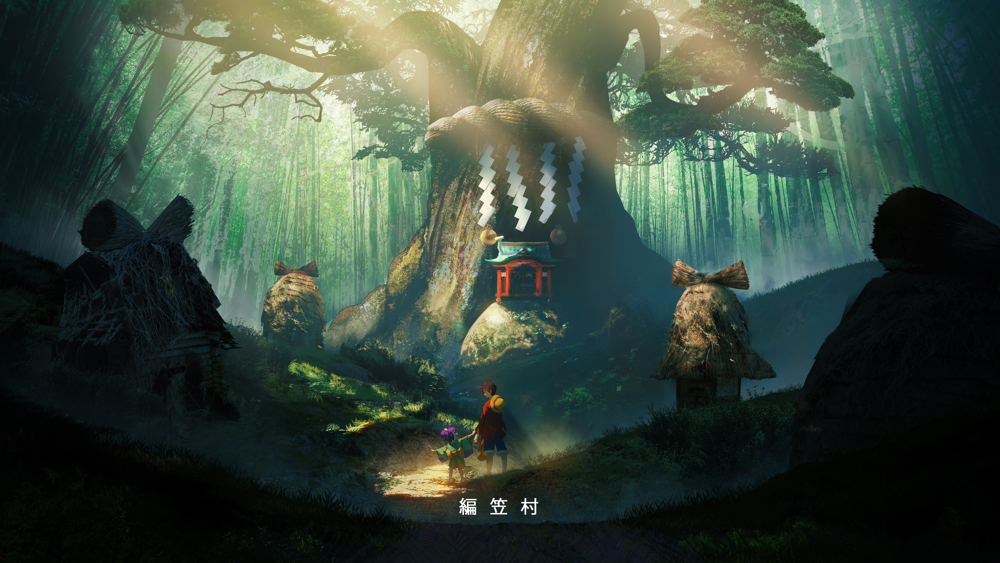

In [2]:
Image('onepiece-image.jpg')

In [3]:
image = cv2.imread('onepiece-image.jpg')
if image is None:
    print('Error Loading Image')
else:
    print('Loaded Successfully')

Loaded Successfully


In [4]:
image

array([[[35, 34, 14],
        [35, 34, 14],
        [35, 34, 14],
        ...,
        [43, 39, 10],
        [43, 39, 10],
        [43, 39, 10]],

       [[35, 34, 14],
        [35, 34, 14],
        [34, 33, 13],
        ...,
        [43, 39, 10],
        [43, 39, 10],
        [43, 39, 10]],

       [[34, 33, 13],
        [34, 33, 13],
        [34, 33, 13],
        ...,
        [43, 39, 10],
        [43, 39, 10],
        [43, 39, 10]],

       ...,

       [[ 8, 14,  9],
        [ 7, 13,  8],
        [ 5, 11,  6],
        ...,
        [ 5,  2,  4],
        [ 5,  2,  4],
        [ 5,  2,  4]],

       [[ 2, 12,  6],
        [ 2, 12,  6],
        [ 1, 11,  5],
        ...,
        [ 4,  2,  2],
        [ 4,  2,  2],
        [ 4,  1,  3]],

       [[ 2, 12,  6],
        [ 2, 12,  6],
        [ 1, 11,  5],
        ...,
        [ 4,  2,  2],
        [ 4,  2,  2],
        [ 4,  1,  3]]], dtype=uint8)

In [5]:
cv2.imshow('window title', image) # opens the window
cv2.waitKey(0) # wait for a key
cv2.destroyAllWindows() # close the window

In [6]:
cv2.imwrite('output.png', image)

True

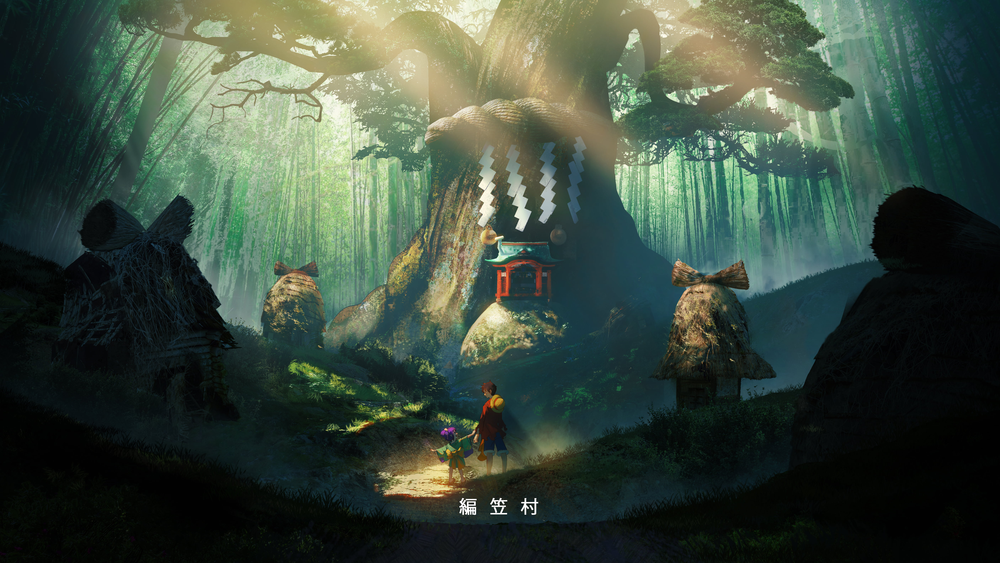

In [7]:
Image('output.png')

In [8]:
image.shape

(3170, 5624, 3)

(height, width, color channel) \
color channel = 3 -> BGR \
if grayscale only (height, width)

In [9]:
h, w, c = image.shape
print(f"Height: {h}, Width: {w}, Color Channel: {c}")

Height: 3170, Width: 5624, Color Channel: 3


Grayscale Conversion

In [4]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
cv2.imshow('grayscale', gray)
cv2.waitKey(0)
cv2.destroyAllWindows()

`cvtColor()` -> convert color type \
`cv2.COLOR_BGR2GRAY` -> BGR to Gray

If grayscale:
- less processing time
- less complexity

In [11]:
cv2.imwrite('gray-onepiece.jpg', gray)

True

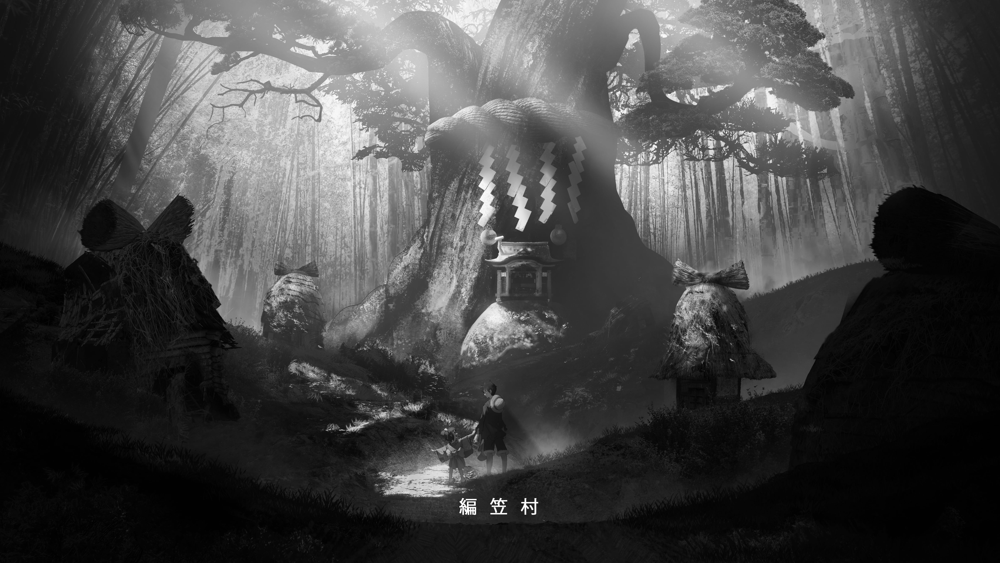

In [12]:
Image('gray-onepiece.jpg')

### Resizing and Scalling Images
```Python
resized = cv2.resize(src, dsize, fx, fy, interpolation)
```
dsize -> dimension in pixels (width, height)  

In [13]:
resized = cv2.resize(gray, (300, 300))
cv2.imshow('original', gray)
cv2.imshow('resized', resized)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Cropping Images using Slicing

In [14]:
cropped = image[100: 200, 50: 300]
cv2.imshow('original', image)
cv2.imshow('cropped', cropped)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Image rotation and Flipping
```Python
M = cv2.getRotationMatrix2D(center, angle, scale)
rotated_image = cv2.warpAffine(image, M. (width, height))
```

In [16]:
(h, w) = resized.shape[:2]
center = (w//2, h//2)
M = cv2.getRotationMatrix2D(center, -90, 1.0)
rotated = cv2.warpAffine(resized, M, (w, h))
cv2.imshow('rotated', rotated)
cv2.waitKey(0)
cv2.destroyAllWindows()

```Python
flipped = cv2.flip(image, flipcode)
```
- flipcode = 0 : flip vertically
- flipcode = 1 : flip horizontally
- flipcode = -1 : both

In [17]:
flipped_horizontal = cv2.flip(resized, 1)
flipped_vertical = cv2.flip(resized, 0)
flipped_both = cv2.flip(resized, -1)

cv2.imshow('horizontal', flipped_horizontal)
cv2.imshow('vertical', flipped_vertical)
cv2.imshow('both', flipped_both)

cv2.waitKey(0)
cv2.destroyAllWindows()

## Basic Image Drawing Techniques
 Drawing a line - `cv2.line()`
```Python
cv2.line(img, pt1, pt2, color, thickness)
```

In [20]:
p1 = (50, 100)
p2 = (100, 200)
color = (0, 0, 255) # BGR
thickness = 4
resized = cv2.resize(image, (300, 300))
cv2.line(resized, p1, p2, color, thickness)
cv2.imshow('image', resized)
cv2.waitKey(0)
cv2.destroyAllWindows()

Drawing a rectangle - `cv2.rectangle()`
```Python
cv2.rectangle(img, pt1, pt2, color, thickness)
```
p1 -> top-left corner of the rectangle \
p2 -> bottom-right corner of the rectangle

In [4]:
(h, w) = image.shape[:2]
resized = cv2.resize(image, (w//10, h//10))

In [25]:
p1 = (10, 50)
p2 = (150, 100)
color = (0, 0, 255)
thickness = 3

cv2.rectangle(resized, p1, p2, color, thickness)

cv2.imshow('IMAGE', resized)
cv2.waitKey(0)
cv2.destroyAllWindows()

Drawing a circle - `cv2.circle()`
```Python
cv2.circle(img, center, radius, color, thickness)
```
radius - pixels \
thickness = -1 : Fills 

In [30]:
circled = resized.copy()
cv2.circle(circled, (100, 100), 50, (255, 0, 255), -1)
cv2.imshow('circled', circled)
cv2.waitKey(0)
cv2.destroyAllWindows()

Adding text - `cv2.putText()`
```Python
cv2.putText(img, text, org, font, fontScale, color, thickness)
```
- org -> bottom left corner of the text

In [5]:
texted = resized.copy()
cv2.putText(texted, "One Piece", (50, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 0, 255), 2)
cv2.imshow('texted', texted)
cv2.waitKey(0)
cv2.destroyAllWindows()

## Video

Video - Collection of images \
Images -> Frames

`cv2.VideoCapture()`
```Python
cap = cv2.VideoCapture(source)
```
- source = 0 : computer webcam
- source = 1 : external webcam

In [7]:
cap = cv2.VideoCapture(0)
while True:
    ret, frame = cap.read() # ret = True/False, frame = image

    if not ret:
        print('Could not read frame')
        break

    cv2.imshow('Webcam', frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        print('Quitting...')
        break

cap.release()
cv2.destroyAllWindows()

Quitting...


Saving Video
```Python
cv2.VideoWriter(filename, codec, fps, frame_size)
```
- codec : compression format
- frame_size : (w, h)

In [8]:
camera = cv2.VideoCapture(0)

frame_width = int(camera.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(camera.get(cv2.CAP_PROP_FRAME_HEIGHT))

codec = cv2.VideoWriter_fourcc(*'XVID')
recorder = cv2.VideoWriter('my_video.avi', codec, 20, (frame_width, frame_height))

while True:
    success, frame = camera.read()

    if not success:
        break

    recorder.write(frame)
    cv2.imshow('Recording', frame)
    
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

camera.release()
recorder.release()
cv2.destroyAllWindows()

### Image Filtering

Gaussian Blur
```Python
blurred_image = cv2.GaussianBlur(image, (kernel_size_x, kernel_size_y), sigma)
```
- kernel_size_x & y : always odd
- Remove Noise
- Smoothening

In [12]:
blurred = cv2.GaussianBlur(resized, (3, 3), 2)
cv2.imshow('Original', resized)
cv2.imshow('Blurred', blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

kernel size
- (3, 3) : light blur
- (9, 9) : strong blur
- (21, 21) : super blur

Median Blur
```Python
blurred = cv2.medianBlur(image, kernel_size)
```

In [6]:
gray = cv2.resize(gray, (w//10, h//10))

In [7]:
blurred = cv2.medianBlur(gray, 5)
cv2.imshow('original', gray)
cv2.imshow('blurred', blurred)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Sharpening
```Python
cv2.filter2D(src, dddept, kernel)
```


In [8]:
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpened = cv2.filter2D(blurred, -1, sharpen_kernel)

cv2.imshow('blurred', blurred)
cv2.imshow('sharpened', sharpened)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Image Processing Flowchart
```mermaid
graph TD
    A[Canny Edge Detection] --> B[Image Thresholding]
    B --> C[Binary Thresholding]
    B --> D[Adaptive Thresholding]
    C --> E[Bitwise Operations]
    D --> E
    E --> F[AND Operation]
    E --> G[OR Operation]
    E --> H[NOT Operation]
```

#### Canny Edge Detection
```Python
edges = cv2.Canny(image, threshold1, threshold2)

    threshold1 : lower boundary to detect weak edges
    threshold2 : upper boundary to detect strong edges
    Image : GrayScale
```

- to detect borders
- seperate objects
- feature extraction
- face detection

#### To read image in grayscale
```Python
img = cv2.imread("image.png", cv2.IMREAD_GRAYSCALE)

In [ ]:
edges = cv2.Canny(gray, 50, 150)
cv2.imshow('gray', gray)
cv2.imshow('edges', edges)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Thresholding in OpenCV
```Python
thresholded_image = cv2.threshold(image, thresh_value, max_value, method)
```
- Image : GrayScale
- THRESH_BINARY : if pixel > thresh_value -> 255 else -> 0

In [14]:
ret, thresh_image = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY)
cv2.imshow('gray', gray)
cv2.imshow('thresholded', thresh_image)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Bitwise Operations

1. Combine two images
2. Cut out image using another image
3. Flip/remove specific areas

```Python
cv2.bitwise_and(img1, img2)
cv2.bitwise_or(img1, img2)
cv2.bitwise_not(img1)
```

In [17]:
img1 = np.zeros((300, 300), dtype="uint8")
img2 = np.zeros((300, 300), dtype="uint8")

cv2.circle(img1, (150, 150), 100, 255, -1)
cv2.rectangle(img2, (100, 100), (250, 250), 255, -1)

bitwise_and = cv2.bitwise_and(img1, img2)
bitwise_or = cv2.bitwise_or(img1, img2)
bitwise_not = cv2.bitwise_not(img1)

cv2.imshow('circle', img1)
cv2.imshow('rectangle', img2)
cv2.imshow('and', bitwise_and)
cv2.imshow('or', bitwise_or)
cv2.imshow('not', bitwise_not)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Contours & Shape Detection

#### Finding Contours
Contour : Curve with continuous edges having same colour and intensity
```Python
contours, hierarchy = cv2.findContours(image, mode, method)
```
- Image : binary (black&white)
- mode : Retrieval mode (how many contours and what type of contours)
    - RETR_EXTERNAL : Outer most shapes
    - RETR_TREE : All Shapes
    - RETR_LIST : All contours Without Hierarchy
- method : Approximation method (How much detail to return for each contour)
- contours : list of all points detected in a shape
- hierarchy : relationships

In [57]:
img = cv2.imread('JollyRoger.jpg')
h, w = img.shape[:2]
img = cv2.resize(img, (w//3, h//3))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2.imshow('JollyRoger', gray)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [58]:
_, thresh = cv2.threshold(gray, 70, 255, cv2.THRESH_BINARY)

In [59]:
# Finding Contours
contours, hierarchy = cv2.findContours(thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

```Python
cv2.drawContours(image, coutours, contour_index, color, thickness)
```
- contour_index = -1 : All contours

In [56]:
cv2.drawContours(img, contours, -1, (0, 0, 200), 3)
cv2.drawContours(gray, contours, -1, (0, 0, 200), 3)
cv2.imshow('Contours image', img)
cv2.imshow('contours gray', gray)
cv2.waitKey(0)
cv2.destroyAllWindows()

#### Shape Detection

```Python
approx = cv2.approxPolyDP(contour, epsilon, True)
```
- epsilon : how close to the real image (smaller the value more closer to the original)
- `0.01 * cv2.arclength(contour, True)` (True: Closed Contour)
- 0.01 - more precise (more closer)
- 0.1 - big

In [60]:
for contour in contours:
    approx = cv2.approxPolyDP(contour, 0.01 * cv2.arcLength(contour, True), True)

    corners = len(approx)

    if corners == 3:
        shape_name = 'Triangle'
    elif corners == 4:
        shape_name = 'Rectangle' 
    elif corners == 5:
        shape_name = 'Pentagon'
    elif corners > 5:
        shape_name = 'Circle'
    else:
        shape_name = 'Unknown'
    
    cv2.drawContours(img, [approx], 0, (0, 0, 200), 2)
    x = approx.ravel()[0]
    y = approx.ravel()[1] - 10
    cv2.putText(img, shape_name, (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (200, 0, 0), 2)

cv2.imshow('contours', img)
cv2.waitKey(0)
cv2.destroyAllWindows()

### Face & Object Detection Process

```mermaid
graph TD
    A[Start] --> B[Haar Cascades]
    B --> C[Face Detection]
    B --> D[Eye Detection]
    B --> E[Smile Detection]
    E --> F[Draw Boxes]
    C --> F
    D --> F
    F --> G[End]
```

In [61]:
face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')

cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(gray, 1.1, 5)
    """
    detectMultiScale - Scan & detect faces
    1.1 - scale factor
    5 - minNeighbours
    """

    for (x, y, w, h) in faces:
        cv2.rectangle(frame, (x, y), (x+w, y+h), (200, 0, 200), 2)

    """
    face = [
    (100, 150, 80, 80), FACE 1
    (250, 120, 90, 90)  FACE 2
    ]

    x - how far from left
    y - how far from top
    w - width of face
    h - height of face
    """

    cv2.imshow('Webcame face detection', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()


In [3]:
face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')
eye_cascade = cv2.CascadeClassifier('haarcascade_eye.xml')
smile_cascade = cv2.CascadeClassifier('haarcascade_smile.xml')

cap = cv2.VideoCapture(0)

while True:
    _, frame = cap.read()
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(gray, 1.1, 5)

    for (x, y, w, h) in faces:
        cv2.rectangle(frame, (x, y), (x+w, y+h), (200, 0, 200), 2)
    
    roi_gray = gray[y : y+h, x : x+w]
    roi_color = frame[y : y+h, x : x+w]

    eyes = eye_cascade.detectMultiScale(roi_gray, 1.1, 10)
    if len(eyes) > 0:
        cv2.putText(frame, 'Eyes Detected', (x, y-30), cv2.FONT_HERSHEY_COMPLEX, 0.6, (0, 255, 0), 2)

    smiles = smile_cascade.detectMultiScale(roi_gray, 1.7, 20)
    if len(smiles) > 0:
        cv2.putText(frame, 'Smile Detected', (x, y-10), cv2.FONT_HERSHEY_COMPLEX, 0.6, (0, 255, 0), 2)

    cv2.imshow('Face', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()